In [7]:
from pathlib import Path

folder = Path(r'C:\Users\sures\Documents\DA Projects\IowaStateCells\Q_interpolated\Release')


In [8]:
import pandas as pd
def get_dataframe(file_name):

    file_name = file_name+'.csv'
    file_path = folder / file_name

    if not file_path.exists():
        print(f'The file {file_name} does not exist')

    with open(file_path, 'r') as file:
        df = pd.read_csv(file, header = None)

    return df



In [9]:
df = get_dataframe('G1C2')

# dQ/dV and Q(V) derived curves for G1C2, G16C1 and G53C2

In [10]:
df_g1c2 = get_dataframe('G1C2')

import numpy as np


voltage = np.linspace(3, 4.2, 1000)
Q_0 = np.asarray(df_g1c2[0])
Q_3 = np.asarray(df_g1c2[2])

dQ_dV_0 = np.gradient(Q_0, voltage)

dQ_dV_3 = np.gradient(Q_3, voltage)



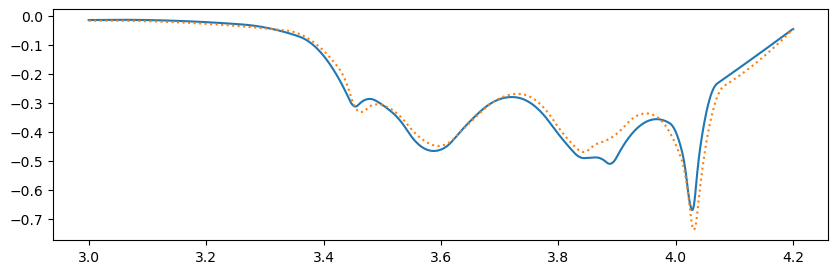

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10, 3))

plt.plot(
    voltage,
    dQ_dV_0,
    label = 'Week 0'
    )
plt.plot(
    voltage,
    dQ_dV_3, 
    linestyle = ':',
    label = 'Week 3'
    )

plt.show()

In [12]:
# A function that returns the dQ/dV for a give input file name

def plot_dV_dQ(group_number :int, cell_number : int, week_number : list):
    '''A function that plots the graphs for dQ/dV for a given group number
    and cell number.
    It needs pandas, numpy and matplotlib.
    '''

    file_name = 'G' + str(group_number) + 'C' + str(cell_number) + '.csv'

    file_path = folder / file_name

    if not file_path.exists():
        print('The file does not exist')

    with open(file_path, 'r') as file:
        df = pd.read_csv(file, header = None)
    norm = plt.Normalize(vmax = max(week_number), vmin = min(week_number))
    cmap = plt.colormaps['inferno']

    voltage = np.linspace(3, 4.2, 1000)
    plt.figure(figsize = (10, 5))
    for week in week_number:

        norm_val = norm(week)

        alpha_val = max(1 - norm_val, 0.15)
        if group_number < 20:
            Q_week = np.asarray(df[week])
            dQ_dV_week = np.gradient(Q_week)

            plt.plot(voltage, dQ_dV_week, color = cmap(norm_val), label = f'Week {week}', alpha = alpha_val)

        else:
            if week != 0:
                week = week + 1

            Q_corrected = np.asarray(df[week])
            dQ_dV_corrected = np.gradient(Q_corrected, voltage)

            plt.plot(voltage, dQ_dV_corrected, color = cmap(norm_val), label = f'Week {week}', alpha = alpha_val)


    plt.legend()
    plt.show()





            
    

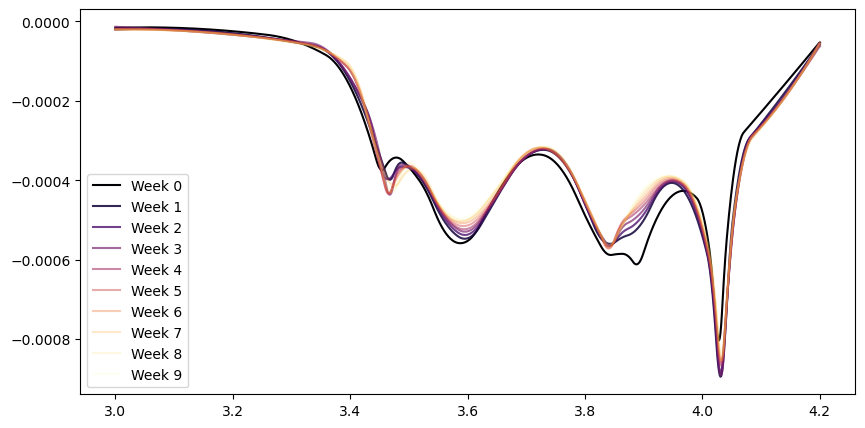

In [13]:
plot_dV_dQ(1, 2, [i for i in range(0, 10)])

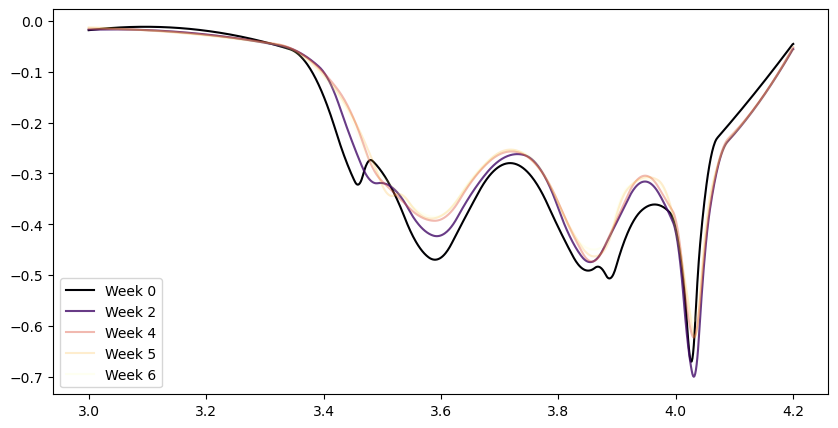

In [14]:
plot_dV_dQ(34, 3, [0, 1, 3, 4, 5])

In [15]:

import pandas as pd
import numpy as np

df = pd.read_csv(r'C:\Users\sures\Documents\DA Projects\IowaStateCells\Q_interpolated\Release 1.0\G1C2.csv', header = None)

Q_0 = df[0]

Q_3 = df[3]

dq = np.gradient((Q_0 - Q_3), voltage)

df__ = pd.DataFrame({'dq' : dq,
                     'voltage': voltage})
variance = np.var(
    df__.loc[
        (df__['voltage'] < end_voltage) &
        (df__['voltage'] > start_voltage),
        'differential'
        ]
    )
    

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\sures\\Documents\\DA Projects\\IowaStateCells\\Q_interpolated\\Release 1.0\\G1C2.csv'

In [16]:
# Searching through the all the possible voltage window of width (0.02)V and extracting the fit with the best Pearson Correlation Coefficient





def variance_extract(group_number: int,
                     cell_id: int,
                     start_voltage: float,
                     end_voltage: float):

    '''Given a certain voltage vintage window and a cell data,
    this function extracts the variance in dQ/dV(difference between week 3 and week 0).
    '''

    file_name = 'G' + str(group_number) + 'C' + str(cell_id) + '.csv'

    file_path = folder/file_name

    if not file_path.exists():
        raise FileNotFoundError(f'Cell file not found: {file_path}')

    with open(file_path, 'r') as file:
        df = pd.read_csv(file, header = None)

    week_3 = 3

    if group_number < 20:
        week_3 = 3

    elif group_number > 20:
        week_3 = 4

    if week_3 not in df.columns:
        return None

    #Lets try differentiating then subtracting. 

    voltage = np.linspace(3, 4.2, 1000)

    dQ_0 = np.gradient(df[0], voltage)

    dQ_3 = np.gradient(df[week_3], voltage)

    dQ = dQ_3 - dQ_0

    df_differential = pd.DataFrame({'voltage' : voltage,
                                    'dQ' : dQ})

    variance = np.mean(
    df_differential.loc[
        (df_differential['voltage'] < end_voltage) &
        (df_differential['voltage'] > start_voltage),
        'dQ'
        ]
    )

    return variance

    
        



In [17]:
variance_extract(2, 3, 3.2, 3.22)

np.float64(-0.007833955930327279)

In [18]:
import get_lifetime
start_voltage = 3.6
end_voltage = 3.9

df_lifetime = pd.DataFrame(columns = ['variance', 'lifetime'])


for group_number in range(1, 65):
    for cell_id in range(1, 5):
        file = 'G' + str(group_number) + "C" + str(cell_id)
        
        try:
            lifetime = get_lifetime.lifetime(file)
            variance = variance_extract(
                group_number,
                cell_id,
                3.6,
                3.9
            )
            

            df_lifetime.loc[len(df_lifetime)] = [
                variance,
                lifetime
            ]

        except KeyError:
            print(f"Skipping G{group_number}C{cell_id}: KeyError")
            continue

        except FileNotFoundError:
            print(f"Skipping G{group_number}C{cell_id}: file not found")
            continue

Skipping G15C1: KeyError
Skipping G15C2: KeyError
Skipping G15C3: KeyError
Skipping G15C4: KeyError
Skipping G26C3: KeyError
Skipping G49C1: KeyError
Skipping G49C2: KeyError
Skipping G49C3: KeyError
Skipping G49C4: KeyError
Skipping G50C1: KeyError
Skipping G50C3: KeyError
Skipping G50C4: KeyError
Skipping G57C1: KeyError
Skipping G57C2: KeyError
Skipping G57C3: KeyError
Skipping G57C4: KeyError
Skipping G58C1: KeyError
Skipping G61C1: KeyError


In [19]:
get_lifetime.lifetime('G1C2')

55.73199074074073

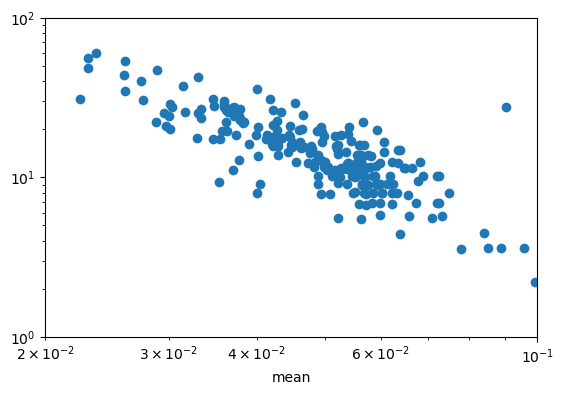

In [20]:
plt.figure(figsize = (6.35, 4.15))

plt.scatter(df_lifetime['variance'], df_lifetime['lifetime'])

plt.xlabel('mean')
plt.yscale('log')
plt.xscale('log')
plt.xlim(0.02, 0.1)
plt.ylim(1, 100)
plt.show()


In [21]:

len(df_lifetime)

238

In [22]:
r = df_lifetime['lifetime'].corr(df_lifetime['variance'], method='pearson')

print(f"Pearson coefficient: {r}")

Pearson coefficient: -0.7126932474996086


In [23]:
log_life = np.log10(df_lifetime['lifetime'])

log_mean = np.log10(df_lifetime['variance'])

# Ignores NaN values automatically
rho = np.ma.corrcoef(np.ma.masked_invalid(log_life), np.ma.masked_invalid(log_mean))[0, 1]


print(rho)

-0.8327672510319405


In [24]:
def plot_Q_V(group_number :int, cell_number : int, week_number : list):
    '''A function that plots the graphs for dQ/dV for a given group number
    and cell number.
    It needs pandas, numpy and matplotlib.
    '''

    file_name = 'G' + str(group_number) + 'C' + str(cell_number) + '.csv'

    file_path = folder / file_name

    if not file_path.exists():
        print('The file does not exist')

    with open(file_path, 'r') as file:
        df = pd.read_csv(file, header = None)
    norm = plt.Normalize(vmax = max(week_number), vmin = min(week_number))
    cmap = plt.colormaps['inferno']

    voltage = np.linspace(3, 4.2, 1000)
    plt.figure(figsize = (10, 5))
    for week in week_number:

        norm_val = norm(week)

        alpha_val = max(1 - norm_val, 0.15)
        if group_number < 20:
            Q_week = np.asarray(df[week])
            

            plt.plot(voltage, Q_week, color = cmap(norm_val), label = f'Week {week}', alpha = alpha_val)

        else:
            if week != 0:
                week = week + 1

            Q_corrected = np.asarray(df[week])
            

            plt.plot(voltage, Q_corrected, color = cmap(norm_val), label = f'Week {week}', alpha = alpha_val)


    plt.legend()
    plt.show()

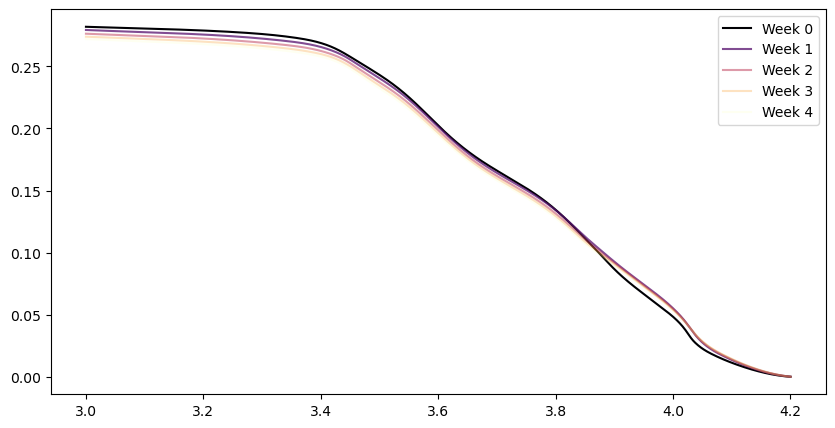

In [25]:
plot_Q_V(2, 1, [0, 1, 2, 3, 4])